In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import energyflow as ef
from energyflow.utils import gen_massless_phase_space
from energyflow import EFPSet
import os
import glob
import time
from RegressFunctions import *
from RestrictedEFPs import efps_chunked
from PhysicsFunctions import *
from scipy.special import gammaln, digamma, polygamma, zeta
from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

os.makedirs('figures', exist_ok=True)

## Import Spectra 

In [2]:
keys = ['Z1', 'Z1_500GeV', 'Z1_1TeV', 'Z1_fix08', 'Z1_fix12', 'Z1_fix16']
depth, nq, M = 4, 2048, 5000

### NTK spectra: λ_k for k = 1..M (dense eigvalsh)
NTK = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/NTK_d{depth}_Q_nq{nq}_M{M}_{k}.npy')}

### reconstructed spectra: rows (k, λ) from the dimension curves
REC_AN = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/Reconstructed_Analytic_{k}.npy')}
REC_PY = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/Reconstructed_Pythia_M{M}_{k}.npy')}

print('NTK:', {k: v.shape for k, v in NTK.items()})
print('analytic:', {k: v.shape for k, v in REC_AN.items()})
print('pythia:', {k: v.shape for k, v in REC_PY.items()})

NTK: {'Z1': (5000,), 'Z1_500GeV': (5000,), 'Z1_1TeV': (5000,), 'Z1_fix08': (5000,), 'Z1_fix12': (5000,), 'Z1_fix16': (5000,)}
analytic: {'Z1': (2, 40), 'Z1_500GeV': (2, 40), 'Z1_1TeV': (2, 40), 'Z1_fix08': (2, 40), 'Z1_fix12': (2, 40), 'Z1_fix16': (2, 40)}
pythia: {'Z1': (2, 50), 'Z1_500GeV': (2, 50), 'Z1_1TeV': (2, 50), 'Z1_fix08': (2, 50), 'Z1_fix12': (2, 50), 'Z1_fix16': (2, 50)}


## Plot Spectra Together 
## (Direct NTK, Reconstructed from Pythia, and Reconstructed from Analytic) 

(1e-07, 2)

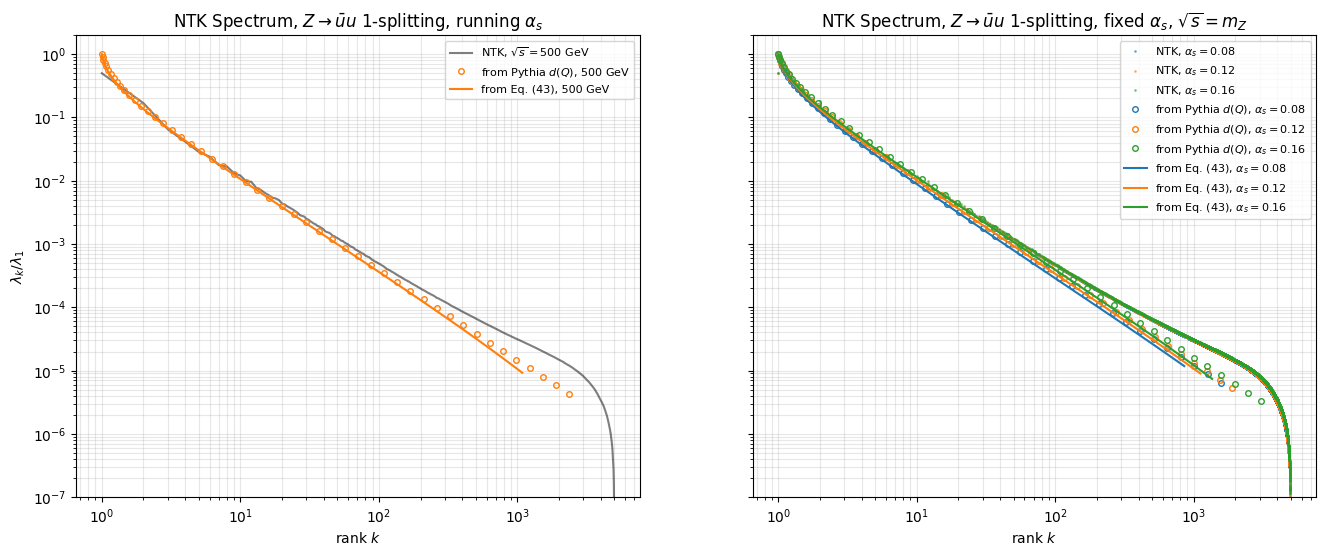

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
kk = lambda lam: np.arange(1, len(lam) + 1)
norm = lambda key, k: NTK[key][int(k[0]) - 1] / NTK[key][0]      # pin a reconstructed curve to the NTK value at its first k
scale = 0.5
# left: energy scan, running alpha_s
# ax1.loglog(kk(NTK['Z1']), scale*NTK['Z1']/NTK['Z1'][0], '.', color='C0', markersize=2, alpha=0.5, label=r'NTK, $\sqrt{s} = m_Z$')
ax1.loglog(kk(NTK['Z1_500GeV']), scale*NTK['Z1_500GeV']/NTK['Z1_500GeV'][0], '.', color='k', markersize=2, alpha=0.5, label=r'NTK, $\sqrt{s} = 500$ GeV')
# ax1.loglog(kk(NTK['Z1_1TeV']), scale*NTK['Z1_1TeV']/NTK['Z1_1TeV'][0], '.', color='C2', markersize=2, alpha=0.5, label=r'NTK, $\sqrt{s} = 1$ TeV')
# k, lam = REC_PY['Z1'];        ax1.loglog(k, lam*norm('Z1', k), 'o', color='C0', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $m_Z$')
k, lam = REC_PY['Z1_500GeV']; ax1.loglog(k, lam*norm('Z1_500GeV', k), 'o', color='C1', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, 500 GeV')
# k, lam = REC_PY['Z1_1TeV'];   ax1.loglog(k, lam*norm('Z1_1TeV', k), 'o', color='C2', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, 1 TeV')
# k, lam = REC_AN['Z1'];        ax1.loglog(k, lam*norm('Z1', k), '-', color='C0', label=r'from Eq. (43), $m_Z$')
k, lam = REC_AN['Z1_500GeV']; ax1.loglog(k, lam*norm('Z1_500GeV', k), '-', color='C1', label=r'from Eq. (43), 500 GeV')
# k, lam = REC_AN['Z1_1TeV'];   ax1.loglog(k, lam*norm('Z1_1TeV', k), '-', color='C2', label=r'from Eq. (43), 1 TeV')
ax1.set_title(r'NTK Spectrum, $Z\rightarrow \bar{u}u$ 1-splitting, running $\alpha_s$'); 
ax1.set_xlabel('rank $k$'); 
ax1.set_ylabel(r'$\lambda_k/\lambda_1$')
ax1.legend(fontsize=8); ax1.grid(True, which='both', alpha=0.3)

# right: fixed alpha_s at mZ
ax2.loglog(kk(NTK['Z1_fix08']), scale*NTK['Z1_fix08']/NTK['Z1_fix08'][0], '.', color='C0', markersize=2, alpha=0.5, label=r'NTK, $\alpha_s = 0.08$')
ax2.loglog(kk(NTK['Z1_fix12']), scale*NTK['Z1_fix12']/NTK['Z1_fix12'][0], '.', color='C1', markersize=2, alpha=0.5, label=r'NTK, $\alpha_s = 0.12$')
ax2.loglog(kk(NTK['Z1_fix16']), scale*NTK['Z1_fix16']/NTK['Z1_fix16'][0], '.', color='C2', markersize=2, alpha=0.5, label=r'NTK, $\alpha_s = 0.16$')
k, lam = REC_PY['Z1_fix08'];  ax2.loglog(k, lam*norm('Z1_fix08', k), 'o', color='C0', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $\alpha_s = 0.08$')
k, lam = REC_PY['Z1_fix12'];  ax2.loglog(k, lam*norm('Z1_fix12', k), 'o', color='C1', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $\alpha_s = 0.12$')
k, lam = REC_PY['Z1_fix16'];  ax2.loglog(k, lam*norm('Z1_fix16', k), 'o', color='C2', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $\alpha_s = 0.16$')
k, lam = REC_AN['Z1_fix08'];  ax2.loglog(k, lam*norm('Z1_fix08', k), '-', color='C0', label=r'from Eq. (43), $\alpha_s = 0.08$')
k, lam = REC_AN['Z1_fix12'];  ax2.loglog(k, lam*norm('Z1_fix12', k), '-', color='C1', label=r'from Eq. (43), $\alpha_s = 0.12$')
k, lam = REC_AN['Z1_fix16'];  ax2.loglog(k, lam*norm('Z1_fix16', k), '-', color='C2', label=r'from Eq. (43), $\alpha_s = 0.16$')
ax2.set_title(r'NTK Spectrum, $Z\rightarrow \bar{u}u$ 1-splitting, fixed $\alpha_s$, $\sqrt{s} = m_Z$'); 
ax2.set_xlabel('rank $k$')
ax2.legend(fontsize=8); ax2.grid(True, which='both', alpha=0.3)
ax1.set_ylim(1e-7, 2)